# Mechanics and thermal

In lumped-element experiments, the static field pushes on the winding and everything bonded to it. Cooling from room temperature contracts parts by different amounts, while supports carry heat from warmer stages.

In this tutorial we compute these three effects on the quick-start toroid: $R=H=2\,\mathrm{m}$, $y=0.6$ and $NI=10^6\,\mathrm{A\,turns}$.

We import axionFEM and set up plotting, run directories and a solve helper for the calculations.

In [1]:
import sys, tempfile
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

try:
    import axionfem as af
except ImportError:                       # running from a source checkout without installing
    sys.path.insert(0, str(Path.cwd().parent / "python"))
    import axionfem as af
from axionfem import plots

print("axionFEM", af.__version__)
MU0 = 1.25663706212e-6                    # [H/m], as in the C++ core
RUNS = Path(tempfile.mkdtemp(prefix="axf_mech_demo_"))   # solver run directories
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True, "grid.color": "#e4e3df",
                     "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
                     "lines.linewidth": 1.8, "legend.frameon": False})
BLUE, ORANGE, GREEN, GOLD, VIOLET, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#6f6e69"


def solve(design, tag, **kw):
    """Solve in RUNS/tag and print the number of unknowns and any solver warning."""
    r = design.solve(RUNS / tag, verbose=0, **kw)
    w = r.data.get("warnings") or []
    print(f"{tag}: {r.data['mesh']['dofs']} DOFs" + (f", warnings: {w}" if w else ""))
    return r

axionFEM 0.1.0


## Magnetic forces

We solve the toroid with `force_samples=5000` to retain one force sample per winding mesh cell in `res.forces["distributions"]` for this mesh.

In [2]:
tor = af.template("toroid", R=2.0, H=2.0)
tor.set(y=0.6)
p = tor.resolved_params()
NI, R, H, y, tw = p["NI"], p["R"], p["H"], p["y"], p["tw"]
res = solve(tor, "toroid", force_samples=5000)     # one force sample per mesh cell of the winding
print(f"L_p = {res.L_p * 1e6:.3f} uH,  Psi = {res.Psi:.4e} H T m^2,  B_max = {res.B_max:.4f} T")

toroid: 85983 DOFs
L_p = 1.458 uH,  Psi = 3.0883e-07 H T m^2,  B_max = 0.1667 T


The force density is $\mathbf f=\mathbf J\times\mathbf B$. Inside an ideal toroid, $B_\varphi=\mu_0NI/(2\pi r)$; outside the winding the field vanishes. A thin winding feels the magnetic pressure on its field-facing surface,

$$
p(r)=\frac{B_\varphi(r)^2}{2\mu_0}.
$$

This pressure pushes outward from the field region: the inner leg toward the axis, the outer leg away from it, and the end legs apart. The corresponding force estimates are

$$
\begin{aligned}
F_{r,\mathrm{inner}}&=-p(yR)\,2\pi yRH,\\
F_{r,\mathrm{outer}}&=+p(R)\,2\pi RH,\\
F_{z,\mathrm{upper}}&=\int_{yR}^{R}\frac{B_\varphi^2}{2\mu_0}\,2\pi r\,dr
=\frac{\mu_0(NI)^2}{4\pi}\ln(1/y).
\end{aligned}
$$

We compare these estimates with the summed FEM forces and report the net force to check force balance.

In [3]:
B_in, B_out = MU0 * NI / (2 * np.pi * y * R), MU0 * NI / (2 * np.pi * R)
p_in, p_out = B_in**2 / (2 * MU0), B_out**2 / (2 * MU0)
print(f"inner leg, r = {y * R:.2f} m: B = {B_in:.4f} T, p = {p_in / 1e3:.2f} kPa")
print(f"outer leg, r = {R:.2f} m: B = {B_out:.4f} T, p = {p_out / 1e3:.2f} kPa")

d = res.forces["distributions"]["toroid"]
r_c, z_c = np.array(d["r_m"]), np.array(d["z_m"])
f_r, f_z = np.array(d["f_r_N"]), np.array(d["f_z_N"])
rows = [("inner leg, F_r", f_r[r_c < y * R].sum(), -p_in * 2 * np.pi * y * R * H),
        ("outer leg, F_r", f_r[r_c > R].sum(), p_out * 2 * np.pi * R * H),
        ("upper half, F_z", f_z[z_c > 0].sum(), MU0 * NI**2 / (4 * np.pi) * np.log(1 / y))]
print(f"\n{'':16s}{'FEM [kN]':>10s}{'estimate [kN]':>15s}")
for name, fem, est in rows:
    print(f"{name:16s}{fem / 1e3:10.2f}{est / 1e3:15.2f}")

F = res.forces
print(f"\nnet axial force on the winding: {F['toroid']['Fz_N']:.1e} N")
print(f"sum over all bodies: {F['closure']['relative']:.1e} of the force scale {F['closure']['force_scale_N'] / 1e3:.1f} kN")

inner leg, r = 1.20 m: B = 0.1667 T, p = 11.05 kPa
outer leg, r = 2.00 m: B = 0.1000 T, p = 3.98 kPa

                  FEM [kN]  estimate [kN]
inner leg, F_r     -168.33        -166.67
outer leg, F_r      100.24         100.00
upper half, F_z      51.97          51.08

net axial force on the winding: -3.9e-10 N
sum over all bodies: -5.7e-15 of the force scale 68.4 kN


The thin-winding estimates agree within $2\,\%$. The radial-force difference comes from the finite $2\,\mathrm{cm}$ leg thickness, across which the field falls to zero, and from the corners. The $F_z$ difference comes from the corners only.

The winding carries its own magnetic load. Its net force is zero to numerical precision, so the supports carry no net magnetic load.

The figure groups cell forces by leg. Left: arrows show load per unit face area, pointing outward from the field region. Right: that pressure is compared with $B_\varphi^2/(2\mu_0)$, with end legs binned in $r$ and inner and outer legs averaged.

We plot the loads and pressures to compare the FEM forces with the thin-winding estimates.

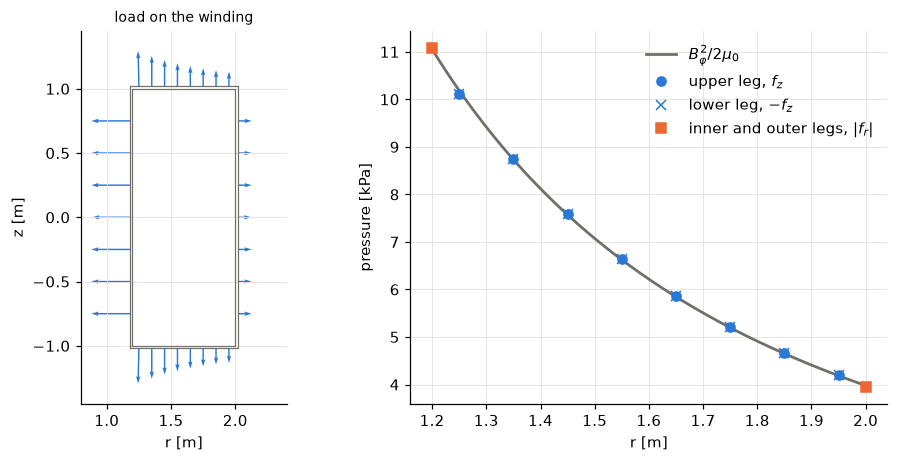

In [4]:
def load(r0, r1, z0, z1, area):
    """Lorentz force of the winding cells with centroids in a box, per unit area of the leg face [Pa]."""
    m = (r_c >= r0) & (r_c < r1) & (z_c >= z0) & (z_c < z1)
    return f_r[m].sum() / area, f_z[m].sum() / area


zb, rb = np.linspace(-0.875, 0.875, 8), np.linspace(y * R, R, 9)
side = [(y * R - tw, (a + b) / 2, *load(y * R - tw, y * R, a, b, 2 * np.pi * y * R * (b - a))) for a, b in zip(zb[:-1], zb[1:])]
side += [(R + tw, (a + b) / 2, *load(R, R + tw, a, b, 2 * np.pi * R * (b - a))) for a, b in zip(zb[:-1], zb[1:])]
top = [((a + b) / 2, H / 2 + tw, *load(a, b, H / 2, H / 2 + tw, np.pi * (b * b - a * a))) for a, b in zip(rb[:-1], rb[1:])]
bot = [((a + b) / 2, -H / 2 - tw, *load(a, b, -H / 2 - tw, -H / 2, np.pi * (b * b - a * a))) for a, b in zip(rb[:-1], rb[1:])]
arrows = np.array(side + top + bot)

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 4.4), gridspec_kw={"width_ratios": [1, 1.6]})
for a, c in ((0.0, GREY), (tw, GREY)):
    ax0.plot([y * R - a, R + a, R + a, y * R - a, y * R - a], [-H / 2 - a, -H / 2 - a, H / 2 + a, H / 2 + a, -H / 2 - a], color=c, lw=0.8)
sc = 0.3 / np.abs(arrows[:, 2:]).max()
ax0.quiver(arrows[:, 0], arrows[:, 1], arrows[:, 2] * sc, arrows[:, 3] * sc, angles="xy", scale_units="xy", scale=1,
           color=BLUE, width=0.007)
ax0.set_aspect("equal")
ax0.set_xlim(0.8, 2.4)
ax0.set_ylim(-1.45, 1.45)
ax0.set_xlabel("r [m]")
ax0.set_ylabel("z [m]")
ax0.set_title("load on the winding", fontsize=9)

r = np.linspace(y * R, R, 200)
ax1.plot(r, (MU0 * NI / (2 * np.pi * r))**2 / (2 * MU0) / 1e3, color=GREY, label=r"$B_\varphi^2/2\mu_0$")
ax1.plot([t[0] for t in top], [t[3] / 1e3 for t in top], "o", color=BLUE, label="upper leg, $f_z$")
ax1.plot([t[0] for t in bot], [-t[3] / 1e3 for t in bot], "x", color=BLUE, label="lower leg, $-f_z$")
ax1.plot([y * R, R], [-np.mean([t[2] for t in side[:7]]) / 1e3, np.mean([t[2] for t in side[7:]]) / 1e3], "s",
         color=ORANGE, label="inner and outer legs, $|f_r|$")
ax1.set_xlabel("r [m]")
ax1.set_ylabel("pressure [kPa]")
ax1.legend()
plt.show()

## Elastic deformation

We add a G10 ring pad in the $1\,\mathrm{cm}$ gap between winding and sheath, a G10 ring post beneath the sheath with a $2\,\mathrm{cm}$ wall and $30\,\mathrm{cm}$ length, and a steel base plate under the post. Touching regions are bonded, with no sliding or separation. Every region whose material has a `mechanical` block belongs to the structure.

Nothing is clamped: both load cases below are self-balanced. The axionFEM solver removes the free axial translation and reports axial displacement relative to the assembly's volume-weighted mean, as the output warning states. Radial rigid motion does not exist in axisymmetry.

The material values are illustrative round numbers: Young's modulus $E$, Poisson ratio $\nu$, total contraction $\alpha$ from room temperature, and conductivity $k(T)$. G10 is orthotropic and is treated here as isotropic. G10 and steel are nonmagnetic, so adding them leaves $L_p$ and $\Psi$ unchanged; the output shows the same $L_p$ before and after.

For axisymmetric, small-strain elasticity,

$$
\nabla\cdot\boldsymbol\sigma+\mathbf f=0,
\qquad
\boldsymbol\sigma=\lambda\,\mathrm{tr}(\boldsymbol\varepsilon)\mathbf I
+2\mu\boldsymbol\varepsilon.
$$

The strains follow from the radial and axial displacements:

$$
\begin{aligned}
\varepsilon_{rr}&=\partial_r u_r,&
\varepsilon_{zz}&=\partial_z u_z,\\
\varepsilon_{\theta\theta}&=\frac{u_r}{r},&
\varepsilon_{rz}&=\tfrac12(\partial_z u_r+\partial_r u_z).
\end{aligned}
$$

The Lamé constants are $\lambda=E\nu/[(1+\nu)(1-2\nu)]$ and $\mu=E/[2(1+\nu)]$.

We define the support materials and geometry to solve for deformation under the magnetic load.

In [5]:
G10 = {"kind": "linear",
       "mechanical": {"E_Pa": 28e9, "nu": 0.21, "alpha": 2.4e-3},
       "thermal": {"k_W_mK": [[4, 0.075], [10, 0.12], [20, 0.18], [50, 0.29], [77, 0.35]]}}
STEEL = {"kind": "linear",
         "mechanical": {"E_Pa": 193e9, "nu": 0.29, "alpha": 2.97e-3},
         "thermal": {"k_W_mK": [[4, 0.3], [77, 8.0]]}}

sup = af.Design(tor.doc)                  # a copy of the quick-start toroid
sup.doc["materials"] = {"g10": G10, "steel": STEEL}
sup.doc["regions"] += [
    # G10 ring in the gap between the winding and the sheath
    {"name": "pad", "material": "g10",
     "shape": {"rect": {"r": [1.5, 1.7], "z": ["-H/2-tw-g", "-H/2-tw"]}}},
    # G10 ring post under the sheath: 2 cm wall, 30 cm long
    {"name": "post", "material": "g10", "mesh_size": 0.01,
     "shape": {"rect": {"r": [1.58, 1.60], "z": ["-H/2-tw-g-ts-0.3", "-H/2-tw-g-ts"]}}},
    # steel base plate under the post
    {"name": "base", "material": "steel",
     "shape": {"rect": {"r": [1.4, 1.8], "z": ["-H/2-tw-g-ts-0.32", "-H/2-tw-g-ts-0.3"]}}},
]
sup.doc["mechanics"] = {}                 # loads from the field only; no clamp
res_m = solve(sup, "supported")
print(f"L_p = {res_m.L_p * 1e6:.3f} uH,  Psi = {res_m.Psi:.4e} H T m^2")

supported: 94747 DOFs, warnings: ['mechanics: no supports were given; each unsupported assembly is free in z (its axial displacement is reported relative to its own volume-weighted mean) and reports no reaction forces']
L_p = 1.458 uH,  Psi = 3.0883e-07 H T m^2


The table lists the largest displacement magnitude and von Mises stress in every part, including the base. The net axial load on the structure is zero, so there is no reaction to carry. The common $0.08\,\mathrm{mm}$ in the sheath, pad, post and base is an axial shift relative to the assembly mean, not deformation.

Two hand formulas explain the printed stress comparisons. A thin leg of thickness $t$ under pressure has hoop stress

$$
\sigma_{\theta\theta}\simeq\mp\frac{pr}{t},
$$

where $r$ is the radius of the loaded face ($yR$ for the inner leg, $R$ for the outer leg), with compression in the inner leg and tension in the outer leg. The two vertical legs also carry the force on the upper half:

$$
\sum_{\mathrm{legs}}\sigma_{zz}A=F_z.
$$

We compare `sample_mech` stresses at $z=0$ with these hoop and axial estimates to check the elastic solution.

In [6]:
PARTS = ["winding", "sheath", "pad", "post", "base"]


def table(r):
    print(f"{'region':8s}{'max |u| [mm]':>14s}{'max von Mises [MPa]':>21s}")
    for k in PARTS:
        v = r.mechanics["regions"][k]
        print(f"{k:8s}{v['u_max_m'] * 1e3:14.3f}{v['von_mises_max_Pa'] / 1e6:21.2f}")


table(res_m)
print(f"net axial load on the structure: {res_m.mechanics['checks']['applied_Fz_N']:.1e} N")

r_legs = np.array([y * R - tw / 2, R + tw / 2])          # mid-planes of the inner and outer legs
s = res_m.sample_mech(r_legs, [0.0, 0.0])
print(f"\nhoop stress at z = 0:  inner {s['sigma_hoop'][0] / 1e6:+.3f} MPa (-p r/t = {-p_in * y * R / tw / 1e6:+.3f}),"
      f"  outer {s['sigma_hoop'][1] / 1e6:+.3f} MPa (p r/t = {p_out * R / tw / 1e6:+.3f})")
A_legs = 2 * np.pi * r_legs * tw
print(f"axial load in the legs: sum of sigma_zz A = {np.sum(s['sigma_zz'] * A_legs) / 1e3:.2f} kN "
      f"(force on the upper half: {rows[2][1] / 1e3:.2f} kN)")

region    max |u| [mm]  max von Mises [MPa]
winding          0.230                 6.46
sheath           0.082                 1.15
pad              0.081                 2.16
post             0.080                 0.35
base             0.081                 0.02
net axial load on the structure: -3.5e-10 N

hoop stress at z = 0:  inner -0.666 MPa (-p r/t = -0.663),  outer +0.394 MPa (p r/t = +0.398)
axial load in the legs: sum of sigma_zz A = 51.83 kN (force on the upper half: 51.97 kN)


The plot shows the winding mid-line with displacements magnified 300 times. Both end legs bow outward; the lower one bends less because the pad ties it to the sheath. At fixed geometry, magnetic stresses scale as $(NI)^2$.

We plot the undeformed and displaced winding mid-lines to show this bending.

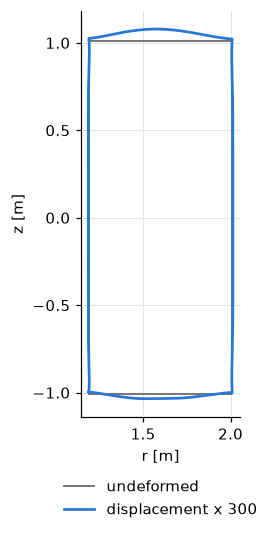

In [7]:
ri, ro, h = y * R - tw / 2, R + tw / 2, H / 2 + tw / 2     # mid-line of the winding
t = np.linspace(0, 1, 200)
path = np.concatenate([np.c_[ri + (ro - ri) * t, -h + 0 * t], np.c_[ro + 0 * t, -h + 2 * h * t],
                       np.c_[ro - (ro - ri) * t, h + 0 * t], np.c_[ri + 0 * t, h - 2 * h * t]])
s = res_m.sample_mech(path[:, 0], path[:, 1])
k = 300
fig, ax = plt.subplots(figsize=(4.2, 4.8))
ax.plot(path[:, 0], path[:, 1], color=GREY, lw=1.2, label="undeformed")
ax.plot(path[:, 0] + k * s["u_r"], path[:, 1] + k * s["u_z"], color=BLUE, label=f"displacement x {k}")
ax.set_aspect("equal")
ax.set_xlabel("r [m]")
ax.set_ylabel("z [m]")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.show()

## Cooldown

`cooldown` adds each material's stress-free strain $\varepsilon^{\mathrm{th}}=-\alpha$, where $\alpha=\int_{T_{\mathrm{op}}}^{293\,\mathrm{K}}\alpha_{\mathrm{lin}}(T)\,dT$ is its positive integrated contraction $\Delta L/L$ from room temperature to the operating temperature. Cooldown assumes every part ends at one uniform temperature. `thermal_strain` stores $-\alpha$. The stress becomes

$$
\boldsymbol\sigma=\lambda\,\mathrm{tr}(\boldsymbol\varepsilon)\mathbf I
+2\mu\boldsymbol\varepsilon+(3\lambda+2\mu)\alpha\mathbf I.
$$

A free body of one material contracts without stress:

$$
\mathbf u=-\alpha\mathbf x,\qquad\boldsymbol\sigma=0.
$$

Bonded parts cannot contract independently. Here $\alpha$ is $3.0\times10^{-3}$ for the winding, $1.43\times10^{-3}$ for the niobium sheath, $2.4\times10^{-3}$ for G10 and $2.97\times10^{-3}$ for steel, so their mismatch creates stress.

The magnetic load remains included. Linear elasticity adds its displacement and stress to those from contraction.

We solve with `cooldown` to report the combined maxima and compare bonded and free radial contraction.

In [8]:
cold = af.Design(sup.doc)
cold.doc["mechanics"]["cooldown"] = True
res_c = solve(cold, "cooldown")
table(res_c)

r_pad = 1.6                                                # just above and just below the pad
s = res_c.sample_mech([r_pad, r_pad], [-H / 2 - tw / 2, -H / 2 - tw - p["g"] - p["ts"] / 2])
print()
for i, name in enumerate(["winding", "sheath"]):
    eps = res_c.mechanics["regions"][name]["thermal_strain"]
    print(f"{name}: u_r = {s['u_r'][i] * 1e3:+.2f} mm at r = {r_pad} m; free contraction -alpha r = {eps * r_pad * 1e3:+.2f} mm")

cooldown: 94747 DOFs, warnings: ['mechanics: no supports were given; each unsupported assembly is free in z (its axial displacement is reported relative to its own volume-weighted mean) and reports no reaction forces']
region    max |u| [mm]  max von Mises [MPa]
winding          9.464                93.94
sheath           5.879               138.88
pad              4.564                65.65
post             4.709                83.67
base             5.520                18.33

winding: u_r = -3.96 mm at r = 1.6 m; free contraction -alpha r = -4.80 mm
sheath: u_r = -3.61 mm at r = 1.6 m; free contraction -alpha r = -2.29 mm


Cooldown stresses reach tens to over a hundred $\mathrm{MPa}$. They are one to two orders of magnitude larger than the magnetic stresses at this current, with a larger ratio in the post. The largest $|u|$ in the table is mostly the free contraction itself, not deformation from the contraction mismatch.

At $r=1.6\,\mathrm{m}$, the pad draws winding and sheath toward a shared contraction: the winding moves $-3.96\,\mathrm{mm}$ instead of its free $-4.80\,\mathrm{mm}$, while the sheath moves $-3.61\,\mathrm{mm}$ instead of $-2.29\,\mathrm{mm}$.

The map shows von Mises stress near the support. The sheath is stressed along its whole width because the pad drags it toward the winding's larger contraction, producing hoop compression in the sheath and hoop tension in the winding. The table maxima and the brightest spots sit at corners of bonded joints, where the elastic solution is singular and the peak grows under mesh refinement. Stresses should be read away from those corners.

We map von Mises stress near the support to show its distribution after cooldown.

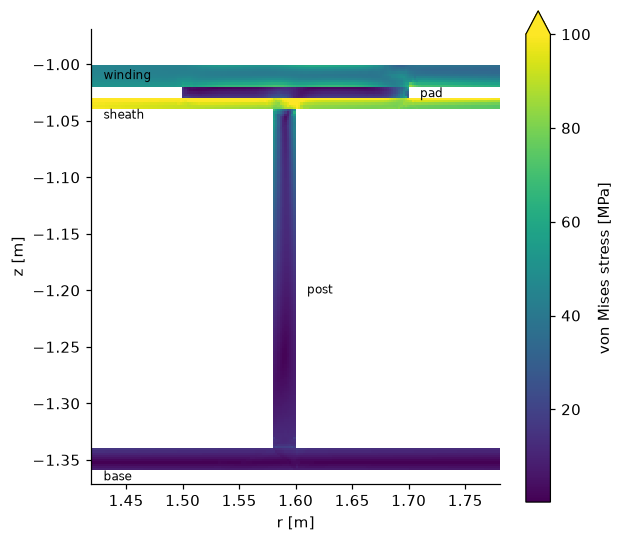

In [9]:
Rg, Zg = np.meshgrid(np.linspace(1.42, 1.78, 180), np.linspace(-1.37, -0.97, 205))
s = res_c.sample_mech(Rg.ravel(), Zg.ravel())
vm = s["von_mises"].reshape(Rg.shape) / 1e6              # NaN outside the structure
fig, ax = plt.subplots(figsize=(6.0, 5.8))
m = ax.pcolormesh(Rg, Zg, vm, shading="auto", cmap="viridis", vmax=100)
fig.colorbar(m, ax=ax, label="von Mises stress [MPa]", extend="max")
for x, z, name in [(1.43, -1.010, "winding"), (1.43, -1.045, "sheath"), (1.71, -1.026, "pad"), (1.61, -1.20, "post"), (1.43, -1.365, "base")]:
    ax.annotate(name, (x, z), fontsize=8, color="k", va="center")
ax.set_aspect("equal")
ax.grid(False)
ax.set_xlabel("r [m]")
ax.set_ylabel("z [m]")
plt.show()

## Heat through the support

This solve is thermal only. Steady conduction obeys

$$
\nabla\cdot\bigl(k(T)\nabla T\bigr)=0.
$$

The axionFEM solver interpolates the material's $k(T)$ table piecewise linearly and uses Picard iteration. We hold only the sheath region at $4.2\,\mathrm{K}$ and the base region at $50\,\mathrm{K}$; all other surfaces are adiabatic. The post carries the whole temperature drop. The bonded pad and winding share the sheath temperature because they have no heat source and their other surfaces are adiabatic. `heat_removed_W` is the heat absorbed by the cold boundary: the load on the $4.2\,\mathrm{K}$ stage.

For a uniform post of area $A$ and length $L$, the Kirchhoff transform is linear along the post:

$$
\theta(T)=\int_{T_c}^{T}k(T')\,dT',
\qquad
Q=\frac{A}{L}\int_{T_c}^{T_h}k(T)\,dT.
$$

We solve steady conduction to compare the FEM heat load with this integral and with estimates using a constant conductivity.

In [10]:
hot = af.Design(sup.doc)
del hot.doc["mechanics"]                  # thermal analysis only
hot.doc["thermal"] = {"fixed": [{"region": "sheath", "T_K": 4.2}, {"region": "base", "T_K": 50.0}]}
res_t = solve(hot, "thermal")
th = res_t.thermal
print(f"heat load on the 4.2 K stage: {th['checks']['heat_removed_W']:.4f} W "
      f"({th['solver']['picard_iterations']} Picard iterations)")

# Kirchhoff transform theta(T) = int_{4.2 K}^T k dT', exact for the piecewise-linear table
Tk, kk = np.array(G10["thermal"]["k_W_mK"]).T
T = np.union1d(np.linspace(4.2, 50.0, 2001), Tk[(Tk > 4.2) & (Tk < 50.0)])
kT = np.interp(T, Tk, kk)
theta = np.concatenate([[0.0], np.cumsum(np.diff(T) * (kT[1:] + kT[:-1]) / 2)])
A_post, L_post = np.pi * (1.60**2 - 1.58**2), 0.3
Q_K = A_post / L_post * theta[-1]
print(f"Kirchhoff: Q = (A/L) int k dT = {Q_K:.4f} W  (relative difference {th['checks']['heat_removed_W'] / Q_K - 1:+.1e})")
for T_ref in (4.2, 50.0):
    print(f"constant k = k({T_ref} K):   Q = {A_post / L_post * np.interp(T_ref, Tk, kk) * (50.0 - 4.2):.4f} W")

thermal: 94747 DOFs
heat load on the 4.2 K stage: 6.0740 W (18 Picard iterations)
Kirchhoff: Q = (A/L) int k dT = 6.0740 W  (relative difference -1.2e-06)
constant k = k(4.2 K):   Q = 2.3335 W
constant k = k(50.0 K):   Q = 8.8460 W


The FEM and Kirchhoff heat loads have a relative difference of $-1.2\times10^{-6}$. Using $k(4.2\,\mathrm{K})$ underestimates the load by a factor of 2.6; using $k(50\,\mathrm{K})$ overestimates it by $46\,\%$.

The post is a continuous ring around the axis. Discrete legs of the same material and length scale the load by their total cross-section.

The temperature profile bends because $k$ grows with $T$. A constant conductivity gives a straight temperature profile.

We plot the FEM, Kirchhoff and constant conductivity temperature profiles to show the effect of $k(T)$.

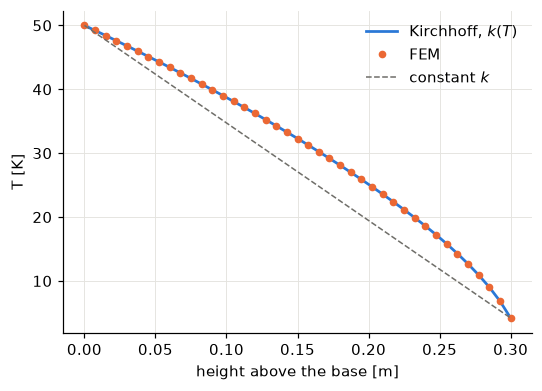

In [11]:
z_top = -H / 2 - tw - p["g"] - p["ts"]                    # post/sheath interface (4.2 K)
z_bot = z_top - L_post                                      # post/base interface (50 K)
z = np.linspace(z_bot, z_top, 41)
s = res_t.sample_mech(np.full_like(z, 1.59), z)
T_exact = np.interp(theta[-1] * (z_top - z) / L_post, theta, T)

fig, ax = plt.subplots(figsize=(5.5, 3.8))
ax.plot(z - z_bot, T_exact, color=BLUE, label=r"Kirchhoff, $k(T)$")
ax.plot(z - z_bot, s["T_K"], "o", ms=4, color=ORANGE, label="FEM")
ax.plot(z - z_bot, 50.0 - (50.0 - 4.2) * (z - z_bot) / L_post, color=GREY, lw=1, ls="--", label="constant $k$")
ax.set_xlabel("height above the base [m]")
ax.set_ylabel("T [K]")
ax.legend()
plt.show()

axionFEM material blocks accept measured values of $E$, $\nu$, $\alpha$ and a $k(T)$ table. For a result object `res`, the full results are available through `res.mechanics`, `res.thermal` and `res.sample_mech(r, z)`.